# v3.2 (Layer G) — factor-aware carry sizing: a NULL result

v3.1 sizes ∝ 1/basis_vol — a **diagonal** risk model. Layer G asks: the funding carry co-moves via a
common leverage/sentiment factor, so the top-K may be *secretly one bet* — should we size on the
**covariance** (`Σ = σ_G²ββᵀ + D`) to diversify that factor? We find: **the book really is a
concentrated factor bet (N_eff ≈ 4), but factor-aware sizing does not help** — it gives up carry
without reducing the tail, because the factor's downside is already vetoed upstream. v3.1 stays best.
All via `lab.py` (engine-parity-checked).

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'svg'
import sys; from pathlib import Path
_p = Path.cwd().resolve()
ROOT = next((q for q in [_p, *_p.parents] if (q/'pyproject.toml').exists()), _p)
sys.path[:0] = [str(ROOT)]
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import research.funding_carry.lab as H
from src.common import config as cfg
plt.rcParams.update({'figure.figsize':(14,3.8),'axes.grid':True,'grid.alpha':0.25,
                     'axes.spines.top':False,'axes.spines.right':False,'font.size':10})
NAVY,TEAL,AMBER,RED,GREY='#1f3a5f','#2a9d8f','#e0a32e','#c1121f','0.6'
COSTS = cfg.load_config('strategies/funding_carry/v3.1.yaml')['costs']
maj, non = H.universe(); P = H.load_panels(maj+non); F,E,didx,syms = P['F'],P['E'],P['didx'],P['symbols']
SIG = H.signal_apr(F,7).reindex(index=didx,columns=syms).where(E)      # EWMA-APR carry signal
SPECS=[{'name':'funding_vol','window':30},{'name':'neg_freq','window':30},{'name':'basis','window':30}]
VETO=[{'feature':'funding_vol','direction':'max','cap':0.75},{'feature':'neg_freq','direction':'max','cap':0.40},{'feature':'basis','direction':'max','cap':0.01}]
feats=H.feature_panels(P,SPECS+[{'name':'basis_vol','window':30}])
veto_ok=H.veto_mask(feats,VETO,SIG)&feats['basis_vol'].notna()&(feats['basis_vol']>0)
Hheld=H.held_matrix(SIG,veto_ok,0.08,0.02,None,None)                  # v3.1's selection (breadth)
Htop=H.held_matrix(SIG,veto_ok,0.08,0.02,15,25)                        # a naive top-15
invvol=1.0/feats['basis_vol'].replace(0.0,np.nan)
G,beta=H.funding_factor(SIG,90)                                        # factor + rolling loadings
print('loaded', SIG.shape, '| avg names held (breadth):', int((Hheld>0).sum(axis=1).mean()))

loaded (1977, 466) | avg names held (breadth): 112


## 1. The carry is factor-driven (basis is not)

Effective number of independent bets `N_eff` across the universe: the **funding signal** we hold on
is dominated by a common factor, while the **basis-return** (daily risk) leg is near-idiosyncratic.
That's why delta-neutral construction leaves idiosyncratic *risk* but the *carry* stays crowded.

In [2]:
rows={}
for tag,X in [('funding signal', SIG),('basis returns', P['L'])]:
    rows[tag]={'N_eff (full)':round(H.neff(X)),
               'N_eff (2021-22)':round(H.neff(X.loc['2021-06-01':'2022-06-01'])),
               'N_eff (2025)':round(H.neff(X.loc['2025-01-01':'2025-09-01'])),
               'names':X.notna().any().sum()}
print(pd.DataFrame(rows).T.to_string())

                N_eff (full)  N_eff (2021-22)  N_eff (2025)  names
funding signal            21                3            10    466
basis returns            147               42            69    466


## 2. Breadth does NOT diversify the carry factor

Track the held book's **funding N_eff** over time. v3.1 holds ~112 names, but in funding-factor terms
it is only ~**4 independent carry bets** — essentially the same as a naive top-15. Funding co-moves so
strongly that holding more names doesn't buy independent carry.

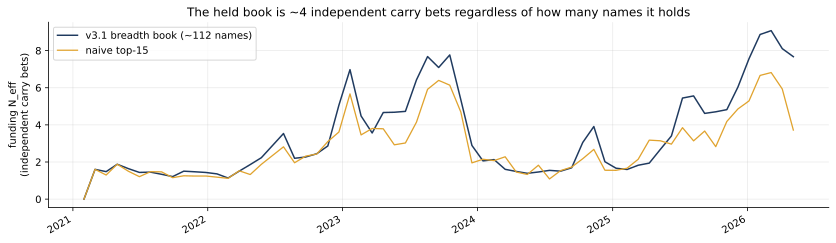

In [3]:
def neff_series(heldmask):
    dts,vals=[],[]
    for d in didx[::30]:
        h=heldmask.loc[d]; h=h[h].index
        if len(h)<5: continue
        v=H.neff(SIG[h].loc[:d].tail(180))
        dts.append(d); vals.append(v)
    return pd.Series(vals,index=dts)
fig,ax=plt.subplots(figsize=(14,3.8))
neff_series(Hheld>0).plot(ax=ax,color=NAVY,lw=1.5,label=f'v3.1 breadth book (~{int((Hheld>0).sum(axis=1).mean())} names)')
neff_series(Htop>0).plot(ax=ax,color=AMBER,lw=1.3,label='naive top-15')
ax.set_ylabel('funding N_eff\n(independent carry bets)'); ax.legend()
ax.set_title('The held book is ~4 independent carry bets regardless of how many names it holds')
plt.show()

## 3. Factor-aware sizing does not help

Three ways to diversify the factor, all vs v3.1 (inverse-basis-vol): a **factor tilt**
(`w ∝ 1/basis_vol · e^(−λβ̂)`), the faithful **one-factor min-var** (`Σ⁻¹1`, Sherman-Morrison, κ =
factor-variance multiplier), and **growth-optimal** `Σ⁻¹a`. Every one underperforms — lower Sharpe
and net, higher turnover, and **no tail improvement** (DD/CVaR/worst-year flat-to-worse).

In [4]:
bhat=beta.sub(beta.mean(axis=1),axis=0).div(beta.std(axis=1),axis=0)   # cross-sectional z of loading
Dvar=feats['basis_vol']**2; sigG=G.rolling(90,min_periods=40).var()
def book_tilt(lam):
    W=H.deadband_weights(H.weights_from_held(Hheld, invvol*np.exp(-lam*bhat)), 0.5)
    return H.book(W,P,COSTS,warmup_days=30)
def book_factor(kappa, growth=False):
    Hn,bt,Dv,sg,a=Hheld.to_numpy(),beta.to_numpy(),Dvar.to_numpy(),sigG.to_numpy(),SIG.to_numpy()
    W=pd.DataFrame(0.0,index=didx,columns=syms)
    for t in range(len(didx)):
        idx=np.where(Hn[t])[0]
        if not len(idx): continue
        b,D,ai=bt[t,idx],Dv[t,idx],a[t,idx]; ok=np.isfinite(b)&np.isfinite(D)&(D>0)
        idx,b,D,ai=idx[ok],b[ok],D[ok],ai[ok]
        if not len(idx): continue
        s2=(sg[t]*kappa) if np.isfinite(sg[t]) else 0.0; Di=1/D; rhs=ai if growth else np.ones_like(b)
        w=Di*rhs - s2*(Di*b)*np.dot(b,Di*rhs)/(1+s2*np.dot(b,Di*b)); w=np.clip(w,0,None)
        if w.sum()>0: W.iloc[t,idx]=w/w.sum()
    return H.book(H.deadband_weights(W,0.5),P,COSTS,warmup_days=30)
def r(tag,res):
    a,b=res['1.0x'],res['2.0x']; wy=min(v['ann_return'] for v in a['by_year'].values())
    return {'Sharpe':a['sharpe'],'Sh@2x':b['sharpe'],'net%':round(a['ann_return']*100,1),
            'maxDD%':round(a['max_drawdown']*100,1),'CVaR':round(a['cvar95']*100,2),
            'worstYr%':round(wy*100,0),'turn':round(a['ann_turnover'],0)}
tab={'v3.1 (inverse-vol)':r('',book_tilt(0.0)),
     'tilt λ=0.5':r('',book_tilt(0.5)),'tilt λ=1.0':r('',book_tilt(1.0)),
     'min-var κ=1':r('',book_factor(1.0)),'min-var κ=10':r('',book_factor(10.0)),
     'growth Σ⁻¹a':r('',book_factor(1.0,growth=True))}
print(pd.DataFrame(tab).T.to_string())

                    Sharpe  Sh@2x  net%  maxDD%  CVaR  worstYr%  turn
v3.1 (inverse-vol)   6.344  3.625   9.3    -2.7 -0.10      -2.0  19.0
tilt λ=0.5           6.311  3.453   9.2    -3.0 -0.10      -2.0  20.0
tilt λ=1.0           5.783  2.607   8.6    -3.5 -0.12      -3.0  23.0
min-var κ=1          5.402  1.314   7.1    -4.2 -0.11      -4.0  27.0
min-var κ=10         5.360  1.300   7.2    -4.1 -0.12      -4.0  27.0
growth Σ⁻¹a          4.845  0.305   7.2    -5.1 -0.12      -5.0  35.0


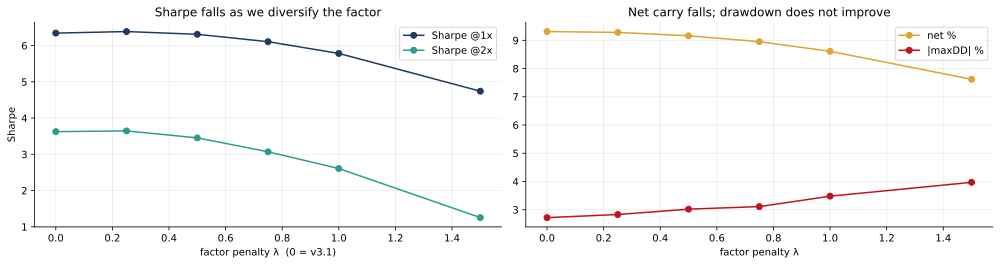

In [5]:
# The trade-off: more factor-penalty (λ) → lower Sharpe & net, no tail gain
lams=[0.0,0.25,0.5,0.75,1.0,1.5]; res=[book_tilt(l) for l in lams]
fig,(a1,a2)=plt.subplots(1,2,figsize=(14,3.8))
a1.plot(lams,[x['1.0x']['sharpe'] for x in res],'-o',color=NAVY,label='Sharpe @1x')
a1.plot(lams,[x['2.0x']['sharpe'] for x in res],'-o',color=TEAL,label='Sharpe @2x')
a1.set_xlabel('factor penalty λ  (0 = v3.1)'); a1.set_ylabel('Sharpe'); a1.legend(); a1.set_title('Sharpe falls as we diversify the factor')
a2.plot(lams,[x['1.0x']['ann_return']*100 for x in res],'-o',color=AMBER,label='net %')
a2.plot(lams,[abs(x['1.0x']['max_drawdown'])*100 for x in res],'-o',color=RED,label='|maxDD| %')
a2.set_xlabel('factor penalty λ'); a2.legend(); a2.set_title('Net carry falls; drawdown does not improve')
plt.tight_layout(); plt.show()

## Conclusion — Layer G not shipped

- **The carry IS a concentrated factor bet** (held-book funding N_eff ≈ 4, even holding ~112 names) —
  the hypothesis was correct about the *structure*.
- **But diversifying it via sizing does not pay.** Tilt, one-factor min-var, and growth-optimal
  Σ⁻¹a all lose to v3.1: lower Sharpe/net, higher turnover, **no drawdown/CVaR/worst-year gain**.
- **Why:** the factor's *downside* (market-wide funding compression/flip) is already handled
  **upstream by selection** — the funding-instability veto (neg-freq/vol caps) and the θ_keep exit
  drop names before they bleed, and the basis veto kills the correlated basis tail. So by sizing time
  the realized tail is already small (DD −3%). Diversifying the carry factor just moves weight off the
  high-carry names (giving up return); the residual *risk* is idiosyncratic basis, which v3.1's
  inverse-vol already sizes optimally. It's concentration in a persistent good thing whose bad tail is
  vetoed.
- **Decision:** keep **v3.1** as the shipped version; **N_eff of the carry (~4) is kept as a
  monitored diagnostic**. The next lever is execution/capacity realism or Layer H (estimation
  hygiene / winner's curse on the *selection*), not factor-aware sizing.